# Beyond Diabetes: charts (Phase 5)

Chart 1, the open areas (hero, 21 Nov): industry-led share of 2023–25 trial starts in the 11 busiest areas, against the white-space bar. Written for a hiring manager on the portfolio site: plain disease names, no jargon. Data: `data/results/05_q2_white_space.csv` (step 05), `03_trial_indications.csv` (trial count) and the GBD PCOS file in `data/external/gbd/`.

Chart 2, the spread timeline (chart 1 until 21 Nov). Rows: indications with 5+ new-area trials up to 2026 (decided 18 Nov). 2026 as hollow dots (decided 12 Nov). Data: `data/results/11_hero_timeline.csv` (step 11) and `04_q1_spread.csv` (first academic and industry-led year).

In [1]:
# Phase 5 charts. Each chart reads only data/results/ CSVs, built by sql/pipeline/run_all.sh.
# Footnote numbers are read from the checks at the end of each pipeline step, never typed from memory.
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")          # run everything from the repo root
os.makedirs("charts", exist_ok=True)

## Chart 1: the open areas (hero)

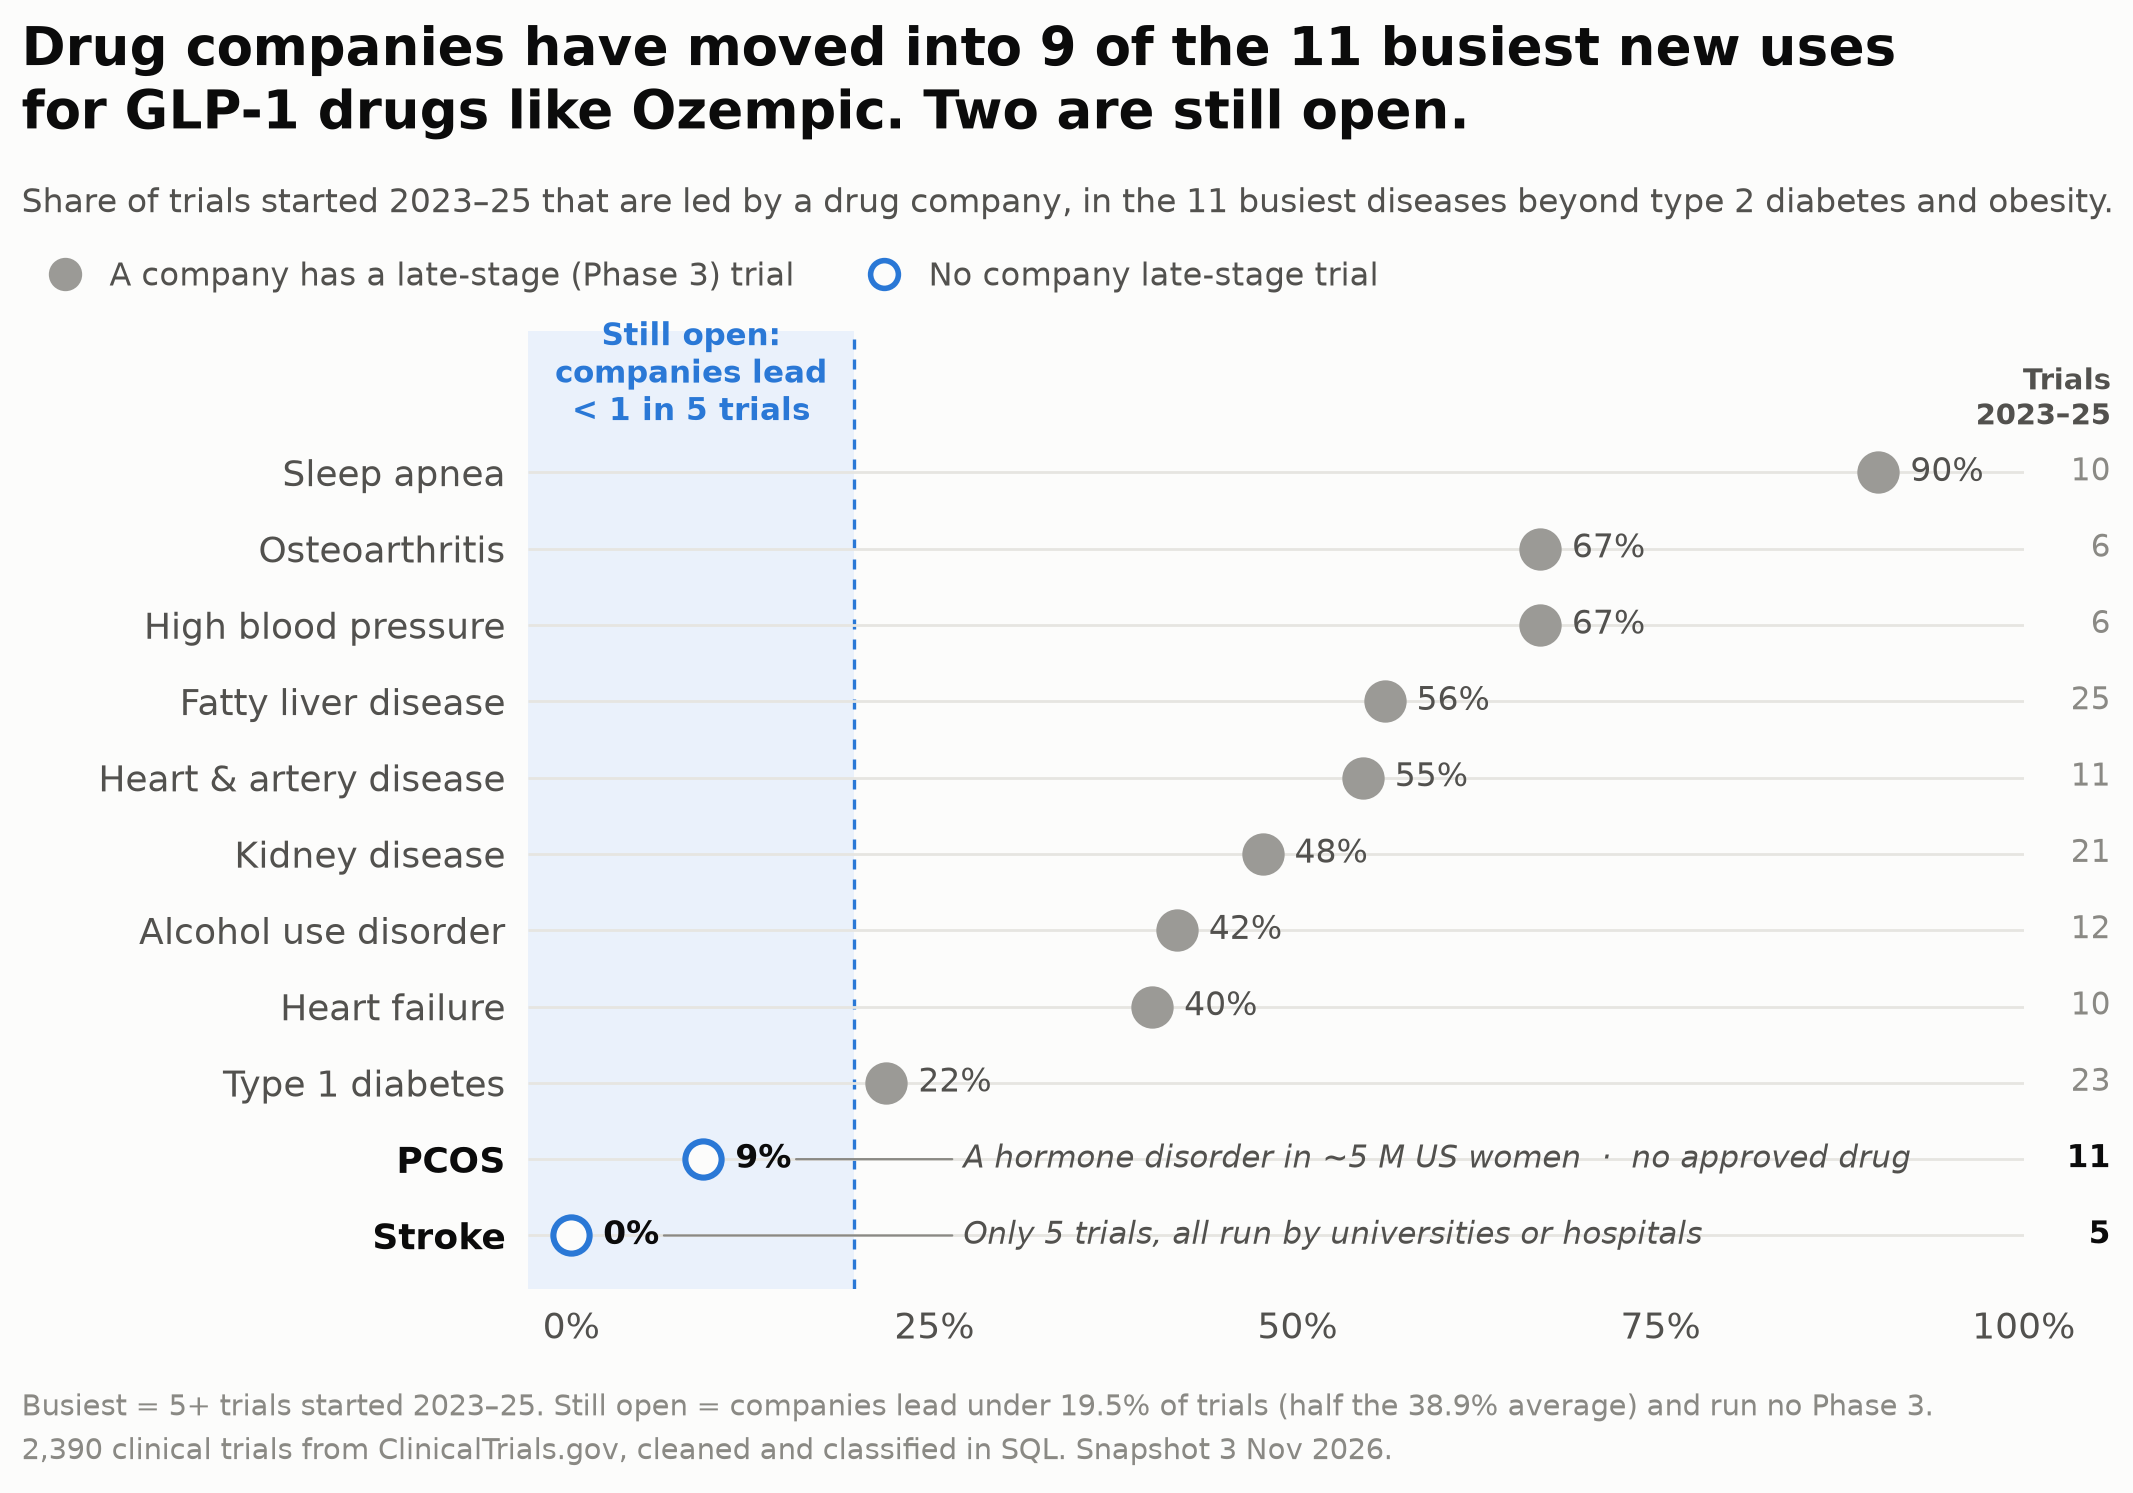

In [2]:
# Chart 1: the open areas (hero, 21 Nov). Reads data/results/ and data/external/gbd/ only;
# writes charts/01_hero_open_areas.png and .svg
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

MIN_RECENT = 5          # rows: indications with 5+ trial starts 2023-25, Q2's size rule

ws = pd.read_csv("data/results/05_q2_white_space.csv")
df = ws[ws["recent_trials"] >= MIN_RECENT].copy()
df["ph3"] = (df["industry_ph3_active"] + df["industry_ph3_completed"]) > 0
df["open"] = df["verdict"].eq("white space")
BAR = df["bar_pct"].iloc[0]                 # 19.5% = half the 38.9% baseline

# Plain names for a non-specialist reader (decided 21 Nov); unlisted names are already plain
PLAIN = {
    "Obstructive sleep apnoea": "Sleep apnea",
    "Hypertension": "High blood pressure",
    "MASLD": "Fatty liver disease",
    "ASCVD": "Heart & artery disease",
    "CKD": "Kidney disease",
}
df["label"] = df["indication"].map(PLAIN).fillna(df["indication"])
df = df.sort_values("industry_share_pct").reset_index(drop=True)

# Numbers in the text, read from files, never typed
n_trials = pd.read_csv("data/results/03_trial_indications.csv")["nct_id"].nunique()
gbd = pd.read_csv("data/external/gbd/gbd_pcos_prevalence_2023_eu27_uk_us_2026-11-14.csv")
pcos_us_m = gbd.query("location_name == 'United States of America' and metric_name == 'Number'")["val"].iloc[0] / 1e6
n_entered = int((~df["open"]).sum())
assert n_entered == len(df) - 2 and len(df) == 11, "headline says 9 of 11: recheck the title"

def pct(x):             # round half up (Python's round() sends 54.5 to 54)
    return f"{int(x + 0.5)}%"

# Colours (reference palette slot 1 for the open areas, the academic colour in chart 2)
SURFACE = "#fcfcfb"; INK = "#0b0b0b"; INK2 = "#52514e"; MUTED = "#8a8984"
GREY = "#9b9a96"; ACCENT = "#2a78d6"; GRID = "#e6e5e1"; ZONE = "#eaf1fb"

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 13})
fig, ax = plt.subplots(figsize=(11, 7.6), dpi=200)
fig.patch.set_facecolor(SURFACE); ax.set_facecolor(SURFACE)

# "Still open" zone: left of the white-space bar
ax.axvspan(-3, BAR, color=ZONE, zorder=0, lw=0)
ax.axvline(BAR, color=ACCENT, lw=1.2, ls=(0, (3, 3)), zorder=1)
ax.text(BAR / 2 - 1.5, len(df) - 0.45, "Still open:\ncompanies lead\n< 1 in 5 trials",
        ha="center", va="bottom", fontsize=11, color=ACCENT, fontweight="bold")

for i, r in df.iterrows():
    c = ACCENT if r["open"] else GREY
    ax.hlines(i, -3, 100, color=GRID, lw=1, zorder=1)
    ax.scatter(r["industry_share_pct"], i, s=170, zorder=3,
               facecolor=c if r["ph3"] else SURFACE, edgecolor=c, linewidth=2.2)
    ax.text(r["industry_share_pct"] + 2.2, i, pct(r["industry_share_pct"]), va="center", fontsize=12,
            color=INK if r["open"] else INK2, fontweight="bold" if r["open"] else "normal")

ax.set_yticks(range(len(df)), df["label"])

# Quiet trial-count column at the right edge (21 Nov): shows size without new ink in the plot
COUNT_X = 106
ax.text(COUNT_X, len(df) - 0.5, "Trials\n2023–25", ha="right", va="bottom", fontsize=10.5,
        color=INK2, fontweight="bold", clip_on=False)
for i, r in df.iterrows():
    ax.text(COUNT_X, i, f"{r['recent_trials']}", ha="right", va="center", fontsize=11,
            color=INK if r["open"] else MUTED, fontweight="bold" if r["open"] else "normal",
            clip_on=False)
for t, o in zip(ax.get_yticklabels(), df["open"]):
    t.set_color(INK if o else INK2); t.set_fontweight("bold" if o else "normal")

# PCOS "so what" note (docs/so_what.md: GBD 2023 count; no FDA or EMA approved drug for PCOS itself)
p = df.index[df["indication"] == "PCOS"][0]
ax.annotate(f"A hormone disorder in ~{pcos_us_m:.0f} M US women  ·  no approved drug",
            xy=(df.loc[p, "industry_share_pct"] + 6, p), xytext=(27, p),
            va="center", fontsize=11, color=INK2, style="italic",
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
# Stroke note: the thinner lead (headline, decided 18 Nov: 5 trials, 0 industry)
s = df.index[df["indication"] == "Stroke"][0]
assert df.loc[s, "industry_led"] == 0, "Stroke note says all academic: recheck"
ax.annotate(f"Only {df.loc[s, 'recent_trials']} trials, all run by universities or hospitals",
            xy=(df.loc[s, "industry_share_pct"] + 6, s), xytext=(27, s),
            va="center", fontsize=11, color=INK2, style="italic",
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))

ax.set_xlim(-3, 100); ax.set_ylim(-0.7, len(df) + 0.85)
ax.set_xticks([0, 25, 50, 75, 100], ["0%", "25%", "50%", "75%", "100%"], color=INK2)
ax.tick_params(length=0, pad=8)
for s in ax.spines.values():
    s.set_visible(False)

fig.text(0.02, 0.965, f"Drug companies have moved into {n_entered} of the {len(df)} busiest new uses\n"
         "for GLP-1 drugs like Ozempic. Two are still open.",
         fontsize=19, fontweight="bold", color=INK, va="top")
fig.text(0.02, 0.855, f"Share of trials started 2023–25 that are led by a drug company, in the {len(df)} busiest "
         "diseases beyond type 2 diabetes and obesity.", fontsize=12, color=INK2, va="top")

legend = [
    Line2D([], [], marker="o", ls="", ms=10, mfc=GREY, mec=GREY, mew=2,
           label="A company has a late-stage (Phase 3) trial"),
    Line2D([], [], marker="o", ls="", ms=10, mfc=SURFACE, mec=ACCENT, mew=2,
           label="No company late-stage trial"),
]
fig.legend(handles=legend, loc="upper left", bbox_to_anchor=(0.012, 0.825), ncol=2,
           frameon=False, fontsize=11.5, labelcolor=INK2, handletextpad=0.4, columnspacing=1.8)

BASE = df["baseline_pct"].iloc[0]
fig.text(0.02, 0.018, f"Busiest = {MIN_RECENT}+ trials started 2023–25. Still open = companies lead under {BAR:g}% "
         f"of trials (half the {BASE:g}% average) and run no Phase 3.\n"
         f"{n_trials:,} clinical trials from ClinicalTrials.gov, cleaned and classified in SQL. "
         "Snapshot 3 Nov 2026.", fontsize=10.5, color=MUTED, linespacing=1.5)

fig.subplots_adjust(left=0.25, right=0.93, top=0.76, bottom=0.13)
fig.savefig("charts/01_hero_open_areas.png", facecolor=SURFACE)
fig.savefig("charts/01_hero_open_areas.svg", facecolor=SURFACE)
plt.show()

## Chart 2: the spread timeline

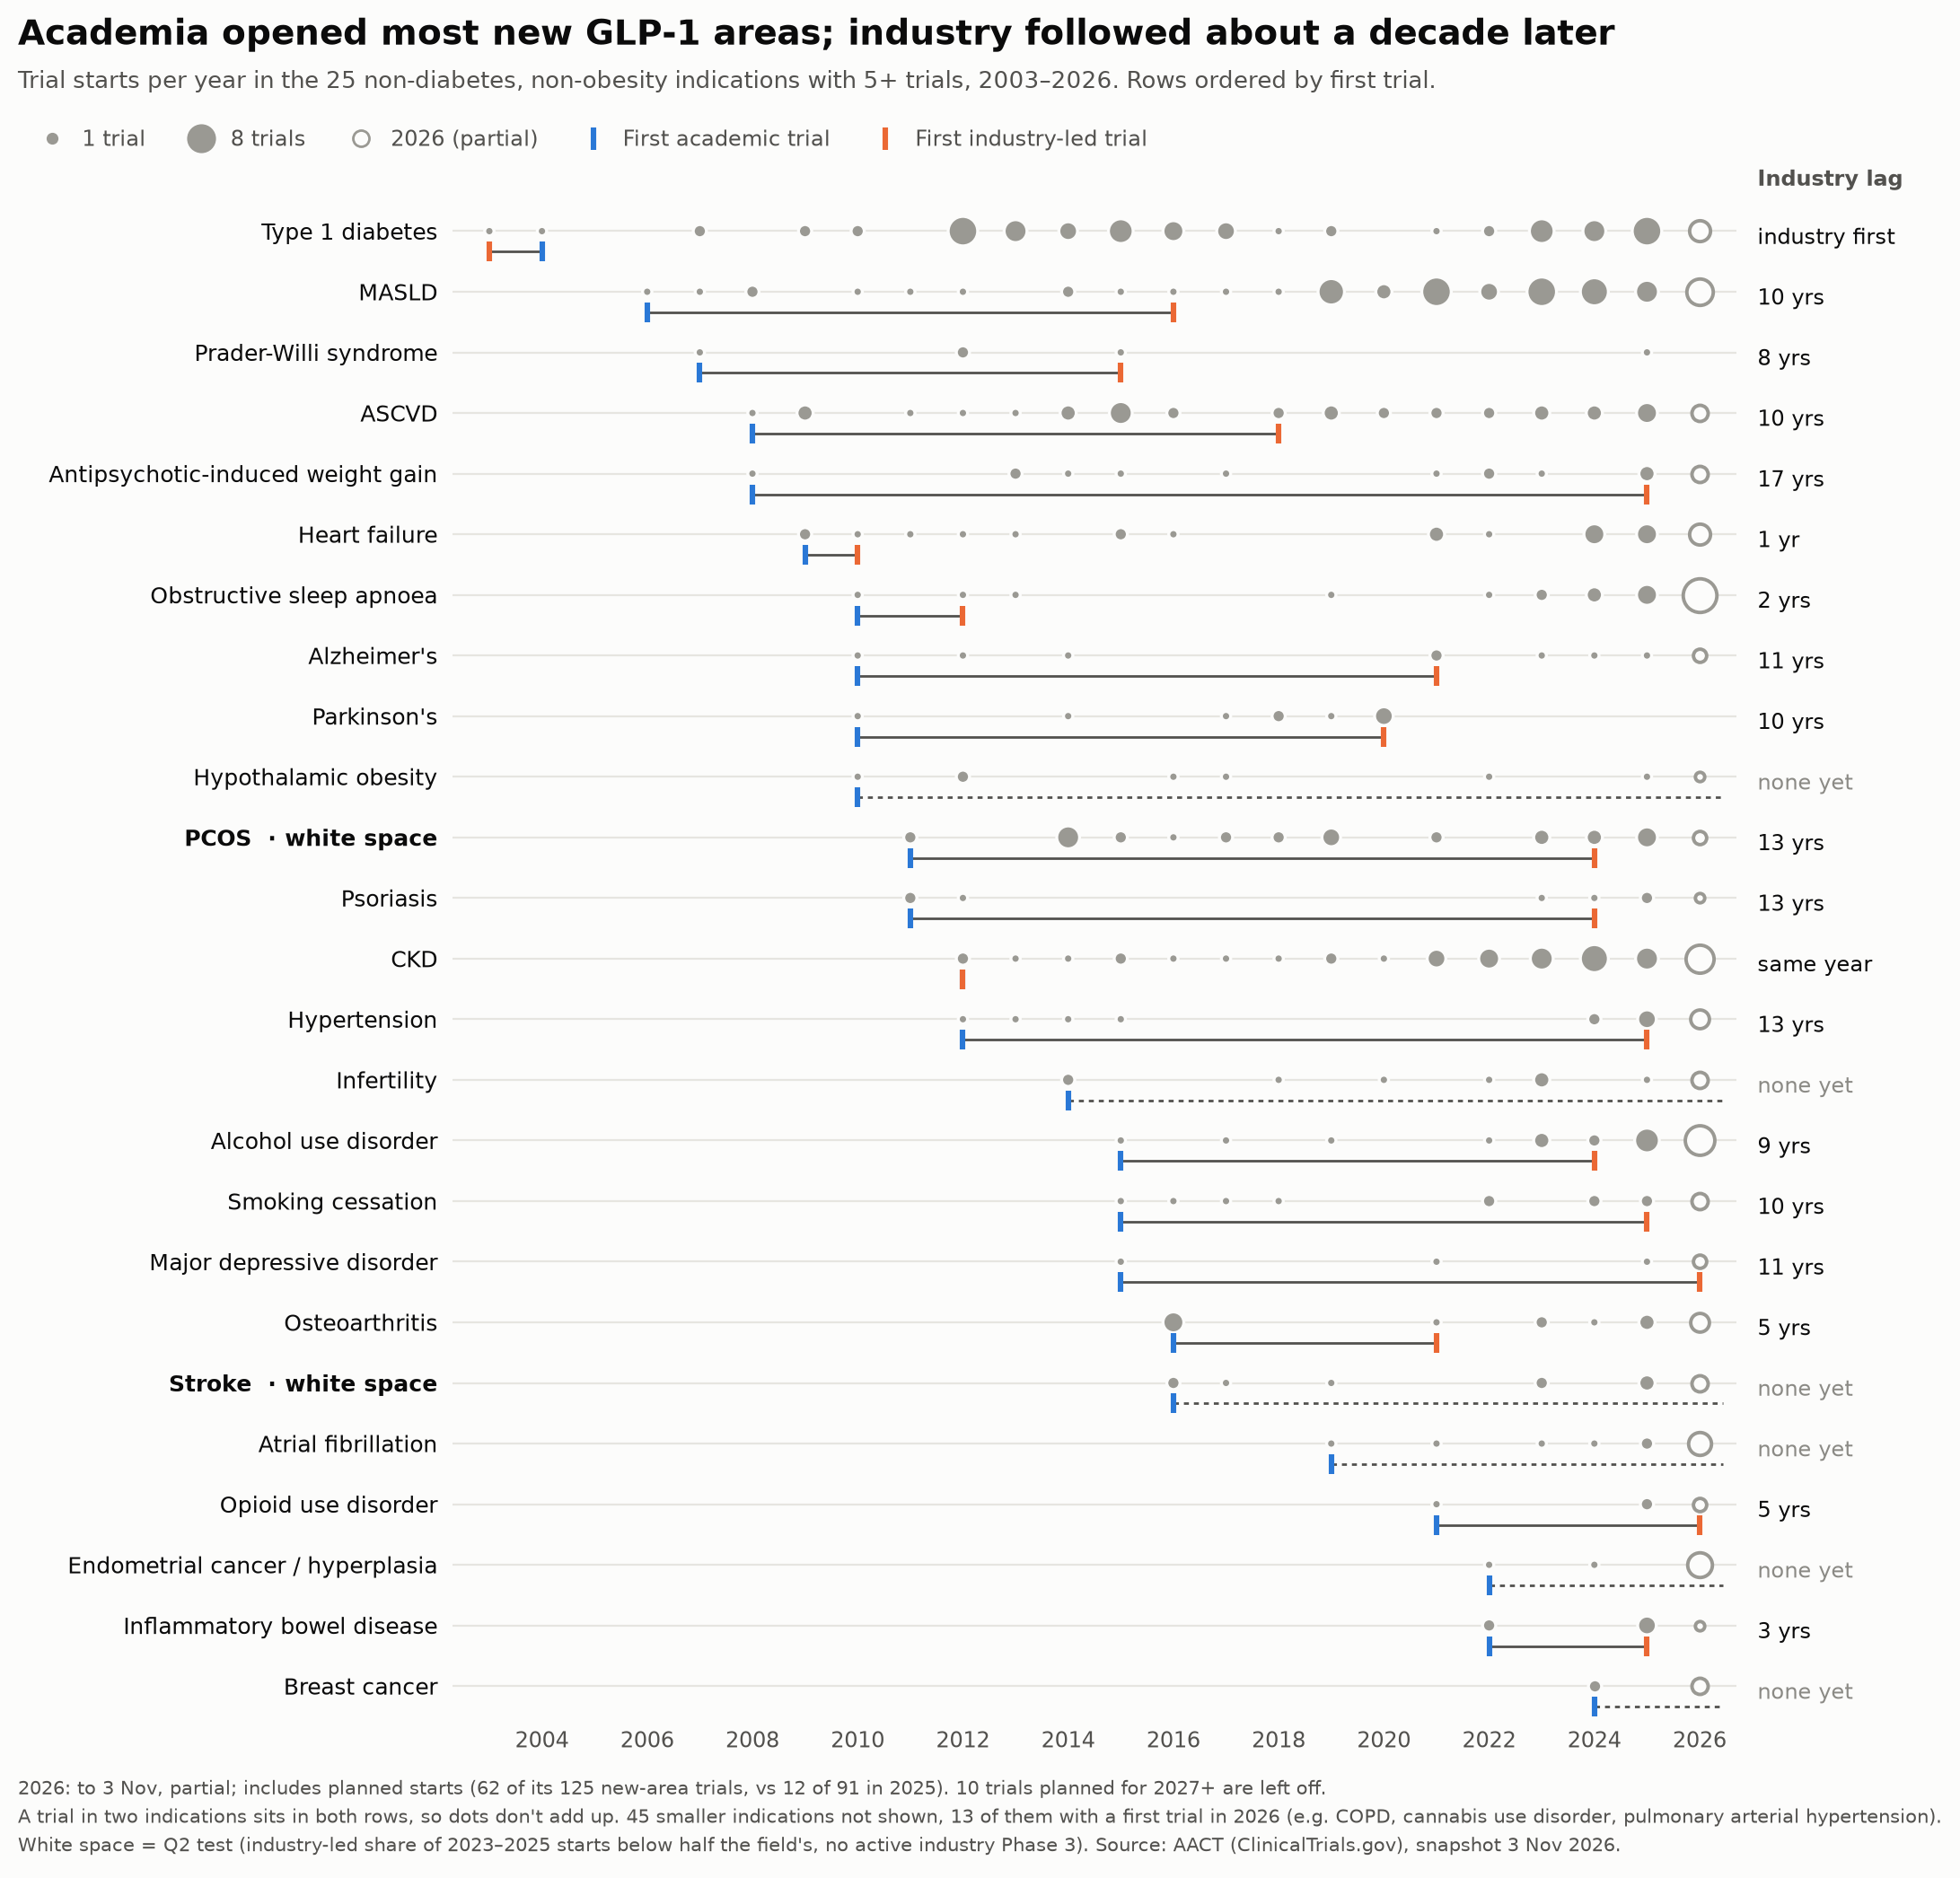

In [3]:
# Chart 2: the spread timeline (chart 1 until 21 Nov). Reads data/results/ only; writes charts/02_spread_timeline.png and .svg
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

MIN_TRIALS = 5          # rows: indications with 5+ new-area trials up to 2026 (decided 18 Nov)
WHITE_SPACE = {"PCOS", "Stroke"}   # from 05_q2_white_space.csv, verdict = white space
FIRST_X, LAST_X = 2003, 2026

# Footnote numbers: read from checks 2-4 of sql/pipeline/11_hero_timeline.sql (18 Nov run)
FOOT_2026_TRIALS, FOOT_2026_PLANNED, FOOT_2027_PLUS = 125, 62, 10
FOOT_2025_TRIALS, FOOT_2025_PLANNED = 91, 12
FOOT_FIRST_2026, FOOT_AREAS = 13, 70

# Colours (reference palette, slots 1-2; neutral ink for dots)
SURFACE = "#fcfcfb"; INK = "#0b0b0b"; INK2 = "#52514e"; MUTED = "#8b8a85"; GRID = "#e6e5e0"
DOT = "#9a9993"; ACADEMIC = "#2a78d6"; INDUSTRY = "#eb6834"

hero = pd.read_csv("data/results/11_hero_timeline.csv")
q1 = pd.read_csv("data/results/04_q1_spread.csv").set_index("indication")
hero["hollow"] = hero["hollow"].eq("t")

totals = hero.groupby("indication")["trials"].sum()
rows = totals[totals >= MIN_TRIALS].index
order = (q1.loc[rows, ["first_year"]].assign(total=totals[rows])
           .sort_values(["first_year", "total"], ascending=[True, False]).index.tolist())
ypos = {ind: i for i, ind in enumerate(order)}

def size(n):            # area proportional to trials
    return 14 * n

fig, ax = plt.subplots(figsize=(11, 10.5), dpi=200)
fig.patch.set_facecolor(SURFACE); ax.set_facecolor(SURFACE)

for ind in order:
    y = ypos[ind]
    ax.axhline(y, color=GRID, lw=0.8, zorder=0)
    d = hero[hero.indication == ind]
    full, part = d[~d.hollow], d[d.hollow]
    ax.scatter(full.start_year, [y] * len(full), s=size(full.trials), color=DOT,
               edgecolor=SURFACE, linewidth=1.2, zorder=3)
    ax.scatter(part.start_year, [y] * len(part), s=size(part.trials), facecolor=SURFACE,
               edgecolor=DOT, linewidth=1.4, zorder=3)

    # lag bracket under the row: first academic trial -> first industry-led trial
    a, i = q1.loc[ind, "first_academic_year"], q1.loc[ind, "first_industry_year"]
    yb = y + 0.34
    if pd.notna(a) and pd.notna(i):
        lo, hi = sorted([a, i])
        ax.plot([lo, hi], [yb, yb], color=INK2, lw=1, zorder=2, solid_capstyle="butt")
    elif pd.notna(a):
        ax.plot([a, LAST_X + 0.45], [yb, yb], color=INK2, lw=1, ls=(0, (2, 2)), zorder=2)
    if pd.notna(a):
        ax.scatter([a], [yb], marker="|", s=60, color=ACADEMIC, linewidth=2.2, zorder=4)
    if pd.notna(i):
        ax.scatter([i], [yb], marker="|", s=60, color=INDUSTRY, linewidth=2.2, zorder=4)

    # right column: lag in years
    lag = q1.loc[ind, "industry_lag_years"]
    txt = ("none yet" if pd.isna(lag) else "industry first" if lag < 0 else "same year" if lag == 0
           else "1 yr" if lag == 1 else f"{int(lag)} yrs")
    ax.text(LAST_X + 1.1, y + 0.12, txt, va="center", ha="left", fontsize=8.5,
            color=INK if pd.notna(lag) else MUTED)

# y labels; white spaces in bold with a tag
ax.set_yticks(range(len(order)))
labels = [f"{ind}  · white space" if ind in WHITE_SPACE else
          ("Endometrial cancer / hyperplasia" if ind.startswith("Endometrial") else ind)
          for ind in order]
ax.set_yticklabels(labels, fontsize=9, color=INK)
for t, ind in zip(ax.get_yticklabels(), order):
    if ind in WHITE_SPACE:
        t.set_fontweight("bold")
ax.set_ylim(len(order) - 0.4, -0.9)
ax.set_xlim(FIRST_X - 0.7, LAST_X + 0.7)
ax.set_xticks(range(2004, 2027, 2))
ax.tick_params(axis="x", labelsize=8.5, colors=INK2, length=0)
ax.tick_params(axis="y", length=0, pad=6)
for s in ax.spines.values():
    s.set_visible(False)
ax.text(LAST_X + 1.1, -0.75, "Industry lag", fontsize=8.5, color=INK2, fontweight="bold")

# titles
fig.text(0.015, 0.975, "Academia opened most new GLP-1 areas; industry followed about a decade later",
         fontsize=14, fontweight="bold", color=INK, ha="left")
fig.text(0.015, 0.952, "Trial starts per year in the 25 non-diabetes, non-obesity indications with 5+ trials, "
         "2003–2026. Rows ordered by first trial.", fontsize=9.5, color=INK2, ha="left")

# legend
leg = [Line2D([], [], marker="o", ls="", markersize=size(1)**0.5, color=DOT, label="1 trial"),
       Line2D([], [], marker="o", ls="", markersize=size(8)**0.5, color=DOT, label="8 trials"),
       Line2D([], [], marker="o", ls="", markersize=size(3)**0.5, markerfacecolor=SURFACE, markeredgecolor=DOT,
              label="2026 (partial)"),
       Line2D([], [], marker="|", ls="", markersize=9, markeredgewidth=2.2, color=ACADEMIC,
              label="First academic trial"),
       Line2D([], [], marker="|", ls="", markersize=9, markeredgewidth=2.2, color=INDUSTRY,
              label="First industry-led trial")]
fig.legend(handles=leg, loc="upper left", bbox_to_anchor=(0.012, 0.94), ncol=5, frameon=False,
           fontsize=8.5, labelcolor=INK2, handletextpad=0.4, columnspacing=1.6)

foot = (f"2026: to 3 Nov, partial; includes planned starts ({FOOT_2026_PLANNED} of its {FOOT_2026_TRIALS} "
        f"new-area trials, vs {FOOT_2025_PLANNED} of {FOOT_2025_TRIALS} in 2025). {FOOT_2027_PLUS} trials planned for 2027+ are left off.\n"
        f"A trial in two indications sits in both rows, so dots don't add up. {FOOT_AREAS - len(order)} smaller "
        f"indications not shown, {FOOT_FIRST_2026} of them with a first trial in 2026 (e.g. COPD, "
        f"cannabis use disorder, pulmonary arterial hypertension).\n"
        "White space = Q2 test (industry-led share of 2023–2025 starts below half the field's, no active "
        "industry Phase 3). Source: AACT (ClinicalTrials.gov), snapshot 3 Nov 2026.")
fig.text(0.015, 0.012, foot, fontsize=7.6, color=INK2, ha="left", va="bottom", linespacing=1.5)

plt.subplots_adjust(left=0.235, right=0.885, top=0.905, bottom=0.085)
fig.savefig("charts/02_spread_timeline.png", facecolor=SURFACE)
fig.savefig("charts/02_spread_timeline.svg", facecolor=SURFACE)
plt.show()